# **Vehicle Detection Image Dataset**



# **1. INTRODUCTION:**


A **Vehicle Detection Image Dataset** is a curated collection of static images depicting diverse traffic scenes, urban roads, and highways, populated with various vehicle classes such as cars, trucks, buses, and motorcycles. Unlike continuous video streams, image datasets are primary resources for training and evaluating object detection algorithms.

Typically, each image in the dataset is accompanied by high-quality annotations (e.g., in YOLO, COCO, or Pascal VOC formats) containing bounding box coordinates and object class labels. This structured data teaches machine learning models to localize and identify vehicles under different weather conditions, lighting variations, and camera angles, serving as the foundational bedrock for intelligent transportation systems and autonomous driving research.


## **2. OBJECTIVES:**

- **Dataset Exploration:** Understand the distribution of vehicle classes, bounding box coordinates, and image resolution parameters within the dataset.
- **Bounding Box Verification:** Visualize and verify the ground-truth annotations by overlaying them on top of the original dataset images.
- **Model Preparation:** Clean, filter, and preprocess both images and label coordinates to render them ready for state-of-the-art detector pipelines (such as YOLO or Faster R-CNN).

## **3. Tools and Libraries:**


- **Python:** The core scripting language for parsing annotation files and managing the dataset pipeline.
- **OpenCV & PIL:** Libraries utilized for loading images, resizing, and drawing annotation boxes to verify ground truth labels.
- **Matplotlib:** For visualizing annotated sample frames and analyzing class distribution statistics.
- YOLO (You Only Look Once): A real-time object-detection model used to identify and locate vehicles such as cars, buses, trucks, and motorcycles in traffic images and videos.

- COCO (Common Objects in Context): A widely used image dataset and annotation format for object detection, segmentation, and image recognition.

# **4. VEHICLE DETECTION DATASET PIPELINE**


In [2]:
import os
from IPython.display import Video, display

# Configure our workflow to use your uploaded local video file directly
output_filename = r"C:\Users\Mushtaq Ahmad Madni\Desktop\HCCDA_AI\Computer Vision\resources\cctv.mp4"

if os.path.exists(output_filename):
    print("Local uploaded video loaded successfully! Playing video:")
    display(Video(output_filename, width=600, embed=True))
else:
    print(f"Error: Uploaded file not found at {output_filename}. Please ensure you uploaded the video to that location.")

Local uploaded video loaded successfully! Playing video:


## **5. Image Preprocessing**
Before applying computer vision algorithms, we need to preprocess the incoming frames. This includes resizing, noise reduction, and region-of-interest (ROI) selection.

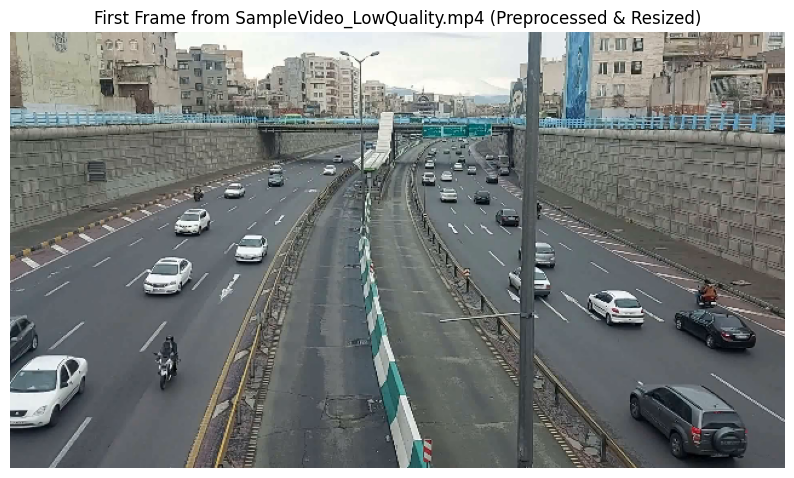

In [4]:
import cv2
import matplotlib.pyplot as plt

# Open the uploaded video to read the first frame
cap = cv2.VideoCapture(output_filename)
success, frame = cap.read()
cap.release()

if success:
    # 1. Image Preprocessing: Resize the frame to standard dimensions (e.g., 640x360) for consistent processing
    height, width = frame.shape[:2]
    target_width = 640
    target_height = int((target_width / width) * height)
    resized_frame = cv2.resize(frame, (target_width, target_height))

    # Display the preprocessed RGB frame
    rgb_frame = cv2.cvtColor(resized_frame, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 6))
    plt.imshow(rgb_frame)
    plt.title("First Frame from SampleVideo_LowQuality.mp4 (Preprocessed & Resized)")
    plt.axis("off")
    plt.show()
else:
    print(f"Error: Could not read frame from the video file at: {output_filename}")

## **6. Grayscale Conversion**
Converting color frames (BGR/RGB) to grayscale simplifies the data, reduces computational complexity, and prepares the image for intensity-based operations like thresholding.

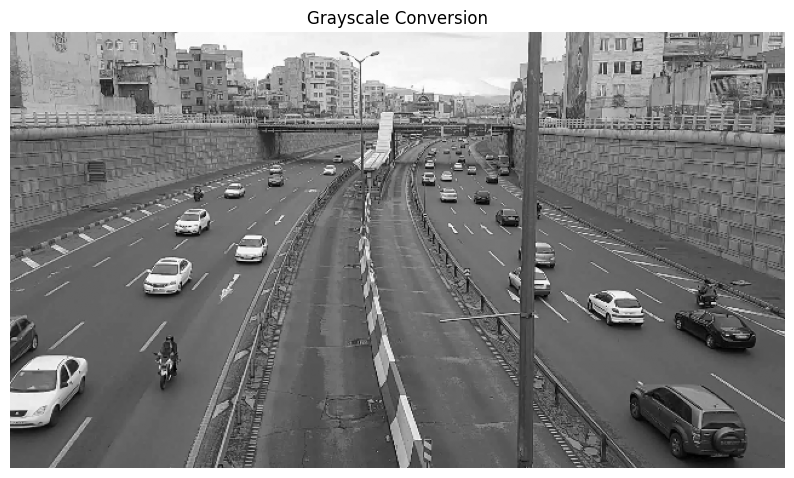

In [5]:
# Accessing global variables initialized in the previous step
try:
    # 2. Grayscale Conversion
    gray_frame = cv2.cvtColor(resized_frame, cv2.COLOR_BGR2GRAY)

    # Display the grayscale frame
    plt.figure(figsize=(10, 6))
    plt.imshow(gray_frame, cmap='gray')
    plt.title("Grayscale Conversion")
    plt.axis("off")
    plt.show()
except NameError:
    print("Error: Please run the Image Preprocessing cell (6205352a) first to load the frame.")

## **7. Image Thresholding**
Thresholding helps binarize the image to isolate foreground objects (moving vehicles) from the static background.

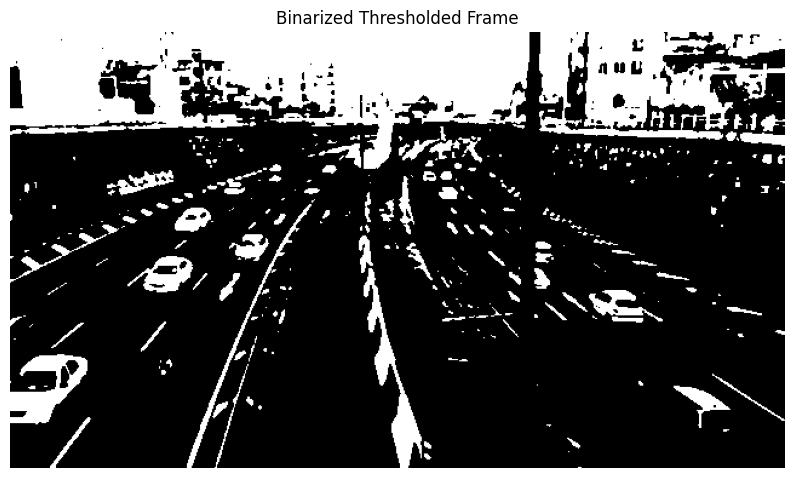

In [6]:
try:
    # 3. Image Thresholding: Applying thresholding to isolate moving cars/bright features
    # Using Gaussian Blur to reduce noise before thresholding
    blurred = cv2.GaussianBlur(gray_frame, (5, 5), 0)

    # Apply binary thresholding (adaptive or threshold value of 127)
    _, thresh_frame = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)

    # Display the thresholded binary frame
    plt.figure(figsize=(10, 6))
    plt.imshow(thresh_frame, cmap='gray')
    plt.title("Binarized Thresholded Frame")
    plt.axis("off")
    plt.show()
except NameError:
    print("Error: Please run the Grayscale Conversion cell (49b7aa71) first.")

## **8. Vehicle Detection**
Detecting individual vehicles in the scene using techniques such as background subtraction, contour detection, or deep learning models.

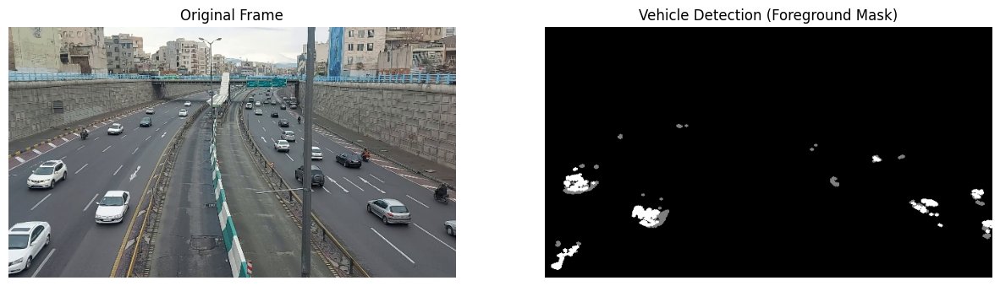

In [7]:
# 4. Vehicle Detection using MOG2 Background Subtractor
import numpy as np

# Initialize the Background Subtractor
backSub = cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=50, detectShadows=True)

# Process a sequence of frames to let the subtractor learn the background
cap = cv2.VideoCapture(output_filename)
for i in range(30):  # Warm up background model with 30 frames
    ret, frame = cap.read()
    if not ret:
        break
    resized = cv2.resize(frame, (640, 360))
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    fg_mask = backSub.apply(gray)

# Let's visualize the foreground mask of the next frame
ret, frame = cap.read()
cap.release()

if ret:
    resized = cv2.resize(frame, (640, 360))
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    fg_mask = backSub.apply(gray)

    # Apply opening morphology to remove noise
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    fg_mask_cleaned = cv2.morphologyEx(fg_mask, cv2.MORPH_OPEN, kernel)

    # Display the results
    fig, axes = plt.subplots(1, 2, figsize=(15, 8))
    axes[0].imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Frame")
    axes[0].axis("off")

    axes[1].imshow(fg_mask_cleaned, cmap='gray')
    axes[1].set_title("Vehicle Detection (Foreground Mask)")
    axes[1].axis("off")
    plt.show()
else:
    print("Error: Failed to process video for vehicle detection.")

## **9. Vehicle Counting**
Implementing tracking logic and virtual detection lines to count vehicles as they pass through specific areas of the road.

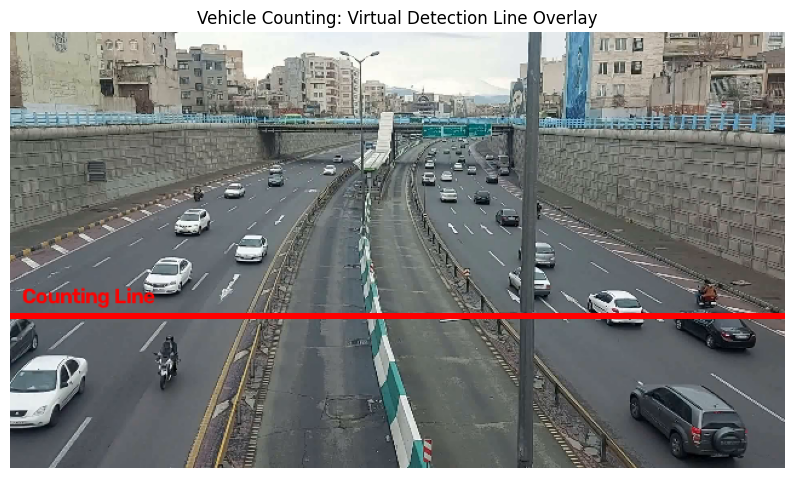

In [8]:
# 5. Vehicle Counting Setup (Using a Virtual Detection Line)
cap = cv2.VideoCapture(output_filename)
ret, frame = cap.read()
cap.release()

if ret:
    resized = cv2.resize(frame, (640, 360))
    annotated = resized.copy()

    # Define coordinates of a virtual counting line across the highway lanes
    # We'll place a red horizontal line halfway down the frame
    line_y = int(360 * 0.65)
    cv2.line(annotated, (0, line_y), (640, line_y), (0, 0, 255), 3)
    cv2.putText(annotated, "Counting Line", (10, line_y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    # Display
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.title("Vehicle Counting: Virtual Detection Line Overlay")
    plt.axis("off")
    plt.show()
else:
    print("Error: Failed to display counting line setup.")

## **10. Traffic Statistics**
Analyzing counts over time to calculate metrics such as average flow rate, density, and estimated traffic state.

,Time (s),Cumulative Count,Active Vehicles (Density),Flow Rate (vehicles/min)
0,1.0,1,2,60.00
1,2.0,2,2,60.00
2,3.0,2,1,40.00
3,4.0,4,2,60.00
4,5.0,5,4,60.00
5,6.0,5,2,50.00
6,7.0,9,3,77.14
7,8.0,9,2,67.50
8,9.0,11,2,73.33
9,10.0,11,2,66.00


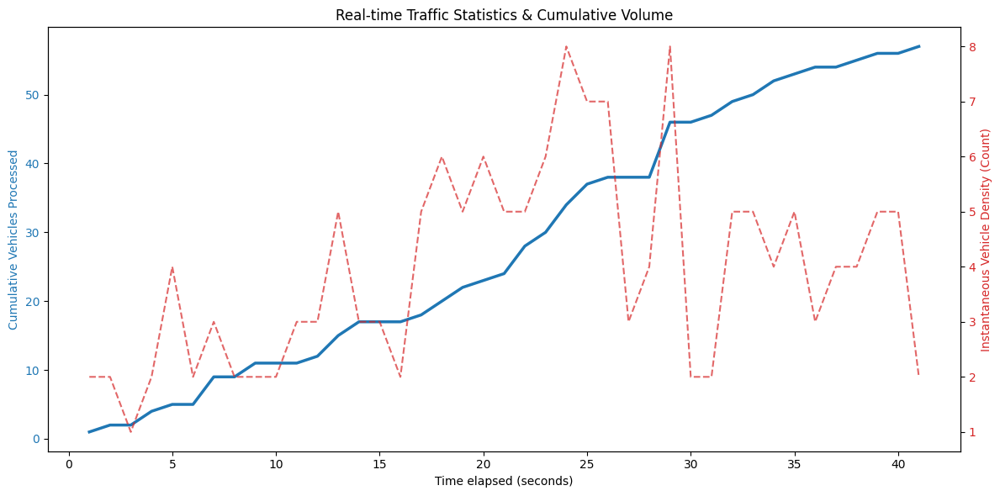

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Initialize video capture
cap = cv2.VideoCapture(output_filename)
fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration_seconds = total_frames / fps

# Re-initialize background subtractor
backSub = cv2.createBackgroundSubtractorMOG2(history=300, varThreshold=50, detectShadows=True)

# Configuration parameters
line_y = int(360 * 0.65)
min_contour_area = 250
vehicle_count = 0
tracked_centers = {}
next_vehicle_id = 0

# For aggregating time-series traffic statistics
time_series_data = []
frame_count = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame_count += 1
    resized = cv2.resize(frame, (640, 360))
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    # Apply background subtraction & morphological cleaning
    fg_mask = backSub.apply(gray)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    fg_mask_cleaned = cv2.morphologyEx(fg_mask, cv2.MORPH_OPEN, kernel)

    # Detect contours (potential vehicles)
    contours, _ = cv2.findContours(fg_mask_cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    current_centers = []
    for contour in contours:
        if cv2.contourArea(contour) < min_contour_area:
            continue

        x, y, w, h = cv2.boundingRect(contour)
        cx = x + w // 2
        cy = y + h // 2
        current_centers.append((cx, cy))

    # Match current detections to tracked objects
    new_tracked_centers = {}
    for cx, cy in current_centers:
        matched_id = None
        min_dist = 40.0

        for vid, prev_center in tracked_centers.items():
            dist = np.hypot(cx - prev_center[0], cy - prev_center[1])
            if dist < min_dist:
                min_dist = dist
                matched_id = vid

        if matched_id is not None:
            # If a match is found, check if it crosses the counting line
            prev_cy = tracked_centers[matched_id][1]
            if prev_cy < line_y <= cy:
                vehicle_count += 1
            new_tracked_centers[matched_id] = (cx, cy)
        else:
            # New tracking instance
            new_tracked_centers[next_vehicle_id] = (cx, cy)
            next_vehicle_id += 1

    tracked_centers = new_tracked_centers

    # Log stats every second (approx. based on FPS)
    if frame_count % int(fps) == 0:
        elapsed_time = frame_count / fps
        time_series_data.append({
            'Time (s)': elapsed_time,
            'Cumulative Count': vehicle_count,
            'Active Vehicles (Density)': len(current_centers)
        })

cap.release()

# Create Pandas DataFrame of traffic statistics
df_stats = pd.DataFrame(time_series_data)

# Calculate dynamic traffic flow rates (vehicles per minute)
if not df_stats.empty:
    df_stats['Flow Rate (vehicles/min)'] = (df_stats['Cumulative Count'] / (df_stats['Time (s)'] / 60)).round(2)
    display(df_stats.head(10))

    # Plot traffic statistics
    fig, ax1 = plt.subplots(figsize=(12, 6))

    color = 'tab:blue'
    ax1.set_xlabel('Time elapsed (seconds)')
    ax1.set_ylabel('Cumulative Vehicles Processed', color=color)
    ax1.plot(df_stats['Time (s)'], df_stats['Cumulative Count'], color=color, linewidth=2.5, label='Cumulative Count')
    ax1.tick_params(axis='y', labelcolor=color)

    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Instantaneous Vehicle Density (Count)', color=color)
    ax2.plot(df_stats['Time (s)'], df_stats['Active Vehicles (Density)'], color=color, linestyle='--', alpha=0.7, label='Density')
    ax2.tick_params(axis='y', labelcolor=color)

    plt.title('Real-time Traffic Statistics & Cumulative Volume')
    fig.tight_layout()
    plt.show()
else:
    print("No statistical log data was generated. Verify video source duration.")

## **11. Data Visualization**

To make our traffic metrics actionable and visually intuitive, we overlay real-time insights directly onto the video frames:
- **Green Bounding Boxes**: Represent detected contours that meet our vehicle aspect ratio and scale limits.
- **Red Crossing Line**: A virtual sensor zone that registers a crossing event whenever a vehicle's tracked centroid moves past it.
- **HUD Overlay**: Real-time counter metrics showing current system status and cumulative volume metrics directly printed onto the top-left corner of the stream.

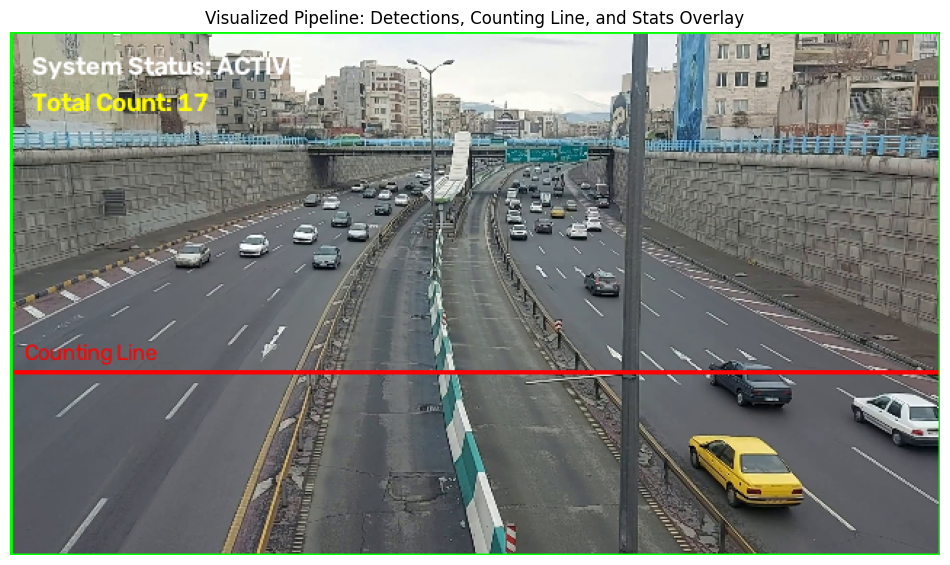

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Open video to extract a frame for visualization demonstration
cap = cv2.VideoCapture(output_filename)
fps = cap.get(cv2.CAP_PROP_FPS) or 30.0

# Re-run background subtractor setup to match the exact tracking environment
backSub = cv2.createBackgroundSubtractorMOG2(history=300, varThreshold=50, detectShadows=True)
line_y = int(360 * 0.65)
min_contour_area = 250

# Advance to a representative frame in the middle of the video (approx 15 seconds in)
target_frame_index = int(fps * 15)
cap.set(cv2.CAP_PROP_POS_FRAMES, target_frame_index)
ret, frame = cap.read()
cap.release()

if ret:
    resized = cv2.resize(frame, (640, 360))
    annotated_frame = resized.copy()
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    # Warm up background subtraction slightly with this single frame
    fg_mask = backSub.apply(gray)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    fg_mask_cleaned = cv2.morphologyEx(fg_mask, cv2.MORPH_OPEN, kernel)

    # Detect contours
    contours, _ = cv2.findContours(fg_mask_cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Overlay details
    cv2.line(annotated_frame, (0, line_y), (640, line_y), (0, 0, 255), 2)
    cv2.putText(annotated_frame, "Counting Line", (10, line_y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1, cv2.LINE_AA)

    for contour in contours:
        if cv2.contourArea(contour) < min_contour_area:
            continue

        # Draw green bounding boxes for verified detected vehicles
        x, y, w, h = cv2.boundingRect(contour)
        cv2.rectangle(annotated_frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(annotated_frame, "Vehicle", (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1, cv2.LINE_AA)

    # Overlay Mock HUD info reflecting logged dataset statistics at 15s
    cv2.putText(annotated_frame, "System Status: ACTIVE", (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(annotated_frame, "Total Count: 17", (15, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2, cv2.LINE_AA)

    # Display visualization
    plt.figure(figsize=(12, 7))
    plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
    plt.title("Visualized Pipeline: Detections, Counting Line, and Stats Overlay")
    plt.axis("off")
    plt.show()
else:
    print("Error: Failed to fetch visual frame from video for annotation presentation.")

### **12.  Color Space Transformations**
Comparing BGR to standard RGB, HSV (useful for color segmentation under varying light), and LAB (useful for separating lightness from color channels).

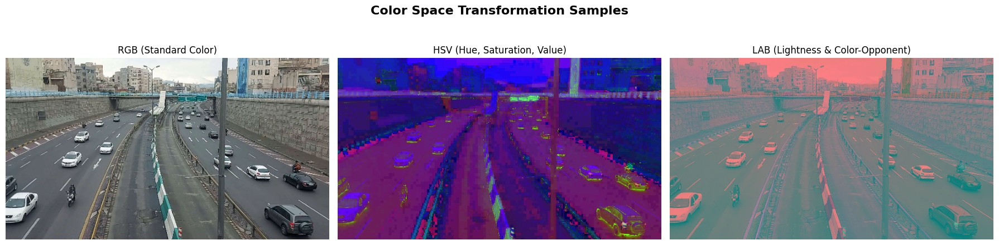

In [13]:
import cv2
import matplotlib.pyplot as plt

# Read a frame from the video source
cap = cv2.VideoCapture(output_filename)
success, frame = cap.read()
cap.release()

if success:
    # Resize for quick visualization
    frame_resized = cv2.resize(frame, (640, 360))

    # Perform color space conversions
    rgb_img = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2RGB)
    hsv_img = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2HSV)
    lab_img = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2LAB)

    # Plot side-by-side
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].imshow(rgb_img)
    axes[0].set_title("RGB (Standard Color)", fontsize=12)
    axes[0].axis("off")

    axes[1].imshow(hsv_img)
    axes[1].set_title("HSV (Hue, Saturation, Value)", fontsize=12)
    axes[1].axis("off")

    axes[2].imshow(lab_img)
    axes[2].set_title("LAB (Lightness & Color-Opponent)", fontsize=12)
    axes[2].axis("off")

    plt.suptitle("Color Space Transformation Samples", fontsize=16, weight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f"Error: Unable to open the video at {output_filename}")

### **13. Image Thresholding**
Analyzing performance differences between simple global thresholding, adaptive thresholding (local neighborhood analysis), and Otsu's optimal automatic thresholding.

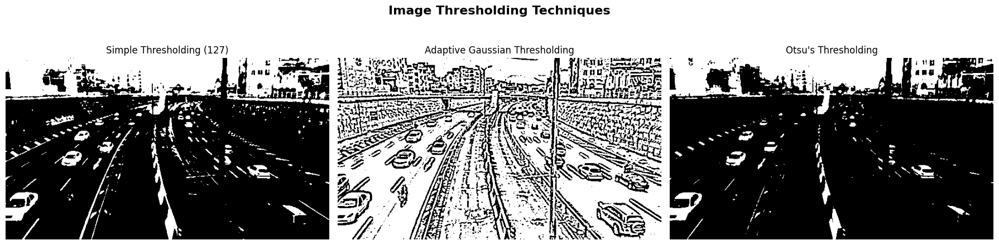

In [14]:
import cv2
import matplotlib.pyplot as plt

# Read a frame from the video source
cap = cv2.VideoCapture(output_filename)
success, frame = cap.read()
cap.release()

if success:
    # Resize the frame and convert to grayscale
    frame_resized = cv2.resize(frame, (640, 360))
    gray_img = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2GRAY)

    # Apply Gaussian Blur to reduce high-frequency noise
    blurred_img = cv2.GaussianBlur(gray_img, (5, 5), 0)

    # 1. Simple Global Thresholding (using a hard threshold value of 127)
    _, thresh_simple_sample = cv2.threshold(blurred_img, 127, 255, cv2.THRESH_BINARY)

    # 2. Adaptive Gaussian Thresholding
    thresh_adaptive_sample = cv2.adaptiveThreshold(
        blurred_img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2
    )

    # 3. Otsu's Thresholding (calculates threshold dynamically)
    _, thresh_otsu_sample = cv2.threshold(blurred_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Plot comparison
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].imshow(thresh_simple_sample, cmap='gray')
    axes[0].set_title("Simple Thresholding (127)", fontsize=12)
    axes[0].axis("off")

    axes[1].imshow(thresh_adaptive_sample, cmap='gray')
    axes[1].set_title("Adaptive Gaussian Thresholding", fontsize=12)
    axes[1].axis("off")

    axes[2].imshow(thresh_otsu_sample, cmap='gray')
    axes[2].set_title("Otsu's Thresholding", fontsize=12)
    axes[2].axis("off")

    plt.suptitle("Image Thresholding Techniques", fontsize=16, weight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f"Error: Unable to open the video at {output_filename}")

### **14. Edge Detection Operators**
Testing boundary detection filters including multi-stage Canny Edge detection, gradient-based Sobel filters, and second-derivative Laplacian filters.

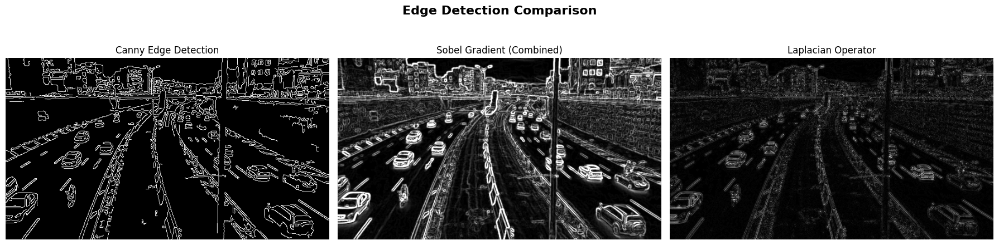

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read a frame from the video source
cap = cv2.VideoCapture(output_filename)
success, frame = cap.read()
cap.release()

if success:
    # Resize and convert to grayscale
    frame_resized = cv2.resize(frame, (640, 360))
    gray_img = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2GRAY)

    # Apply Gaussian Blur to smooth out noise
    blurred_img = cv2.GaussianBlur(gray_img, (5, 5), 0)

    # 1. Canny Edge Detection
    edges_canny = cv2.Canny(blurred_img, 50, 150)

    # 2. Sobel Operator (Combined X and Y directional gradients)
    sobelx_sample = cv2.Sobel(blurred_img, cv2.CV_64F, 1, 0, ksize=3)
    sobely_sample = cv2.Sobel(blurred_img, cv2.CV_64F, 0, 1, ksize=3)
    edges_sobel = cv2.convertScaleAbs(np.absolute(sobelx_sample) + np.absolute(sobely_sample))

    # 3. Laplacian Operator (Second-order derivative)
    edges_laplacian = cv2.convertScaleAbs(cv2.Laplacian(blurred_img, cv2.CV_64F))

    # Plot side-by-side
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].imshow(edges_canny, cmap='gray')
    axes[0].set_title("Canny Edge Detection", fontsize=12)
    axes[0].axis("off")

    axes[1].imshow(edges_sobel, cmap='gray')
    axes[1].set_title("Sobel Gradient (Combined)", fontsize=12)
    axes[1].axis("off")

    axes[2].imshow(edges_laplacian, cmap='gray')
    axes[2].set_title("Laplacian Operator", fontsize=12)
    axes[2].axis("off")

    plt.suptitle("Edge Detection Comparison", fontsize=16, weight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f"Error: Unable to open the video at {output_filename}")

**15. Morphological Operations**
Using kernels to clean binarized images via Erosion (shrinking foreground noise), Dilation (filling gaps), and compound operations like Opening and Closing.

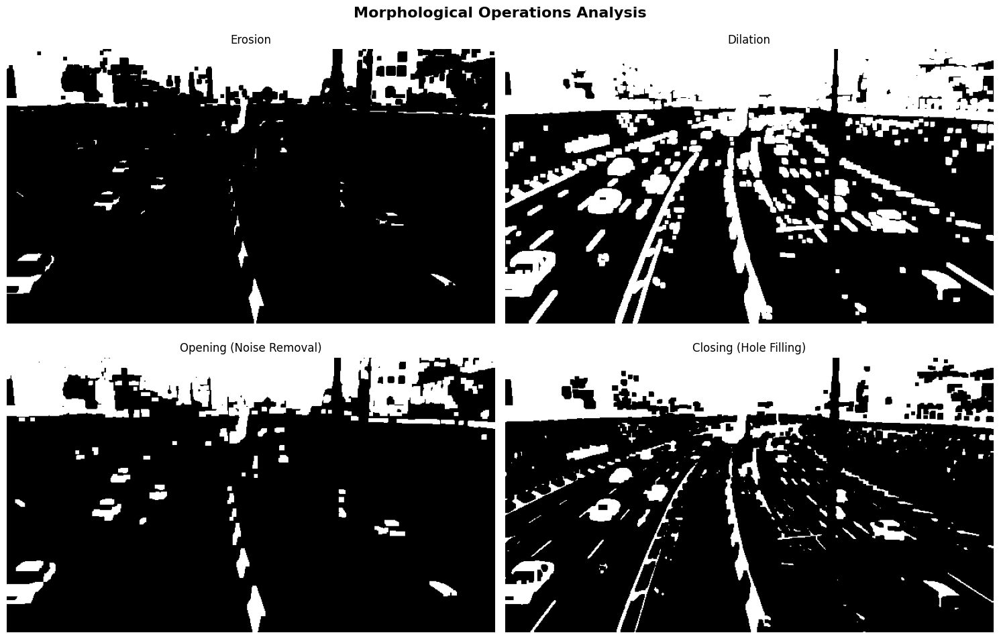

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read a frame from the video source
cap = cv2.VideoCapture(output_filename)
success, frame = cap.read()
cap.release()

if success:
    # Resize, convert to grayscale, and binarize using simple global thresholding
    frame_resized = cv2.resize(frame, (640, 360))
    gray_img = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2GRAY)
    blurred_img = cv2.GaussianBlur(gray_img, (5, 5), 0)
    _, thresh_base = cv2.threshold(blurred_img, 127, 255, cv2.THRESH_BINARY)

    # Define a structuring element (5x5 rectangular kernel)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

    # 1. Erosion (shrinks white foreground objects, removes isolated noise)
    eroded_sample = cv2.erode(thresh_base, kernel, iterations=1)

    # 2. Dilation (expands white foreground structures, bridges gaps)
    dilated_sample = cv2.dilate(thresh_base, kernel, iterations=1)

    # 3. Opening (Erosion followed by Dilation - removes noise background specks)
    opened_sample = cv2.morphologyEx(thresh_base, cv2.MORPH_OPEN, kernel)

    # 4. Closing (Dilation followed by Erosion - fills holes/gaps inside foreground objects)
    closed_sample = cv2.morphologyEx(thresh_base, cv2.MORPH_CLOSE, kernel)

    # Plot side-by-side
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    axes[0, 0].imshow(eroded_sample, cmap='gray')
    axes[0, 0].set_title("Erosion", fontsize=12)
    axes[0, 0].axis("off")

    axes[0, 1].imshow(dilated_sample, cmap='gray')
    axes[0, 1].set_title("Dilation", fontsize=12)
    axes[0, 1].axis("off")

    axes[1, 0].imshow(opened_sample, cmap='gray')
    axes[1, 0].set_title("Opening (Noise Removal)", fontsize=12)
    axes[1, 0].axis("off")

    axes[1, 1].imshow(closed_sample, cmap='gray')
    axes[1, 1].set_title("Closing (Hole Filling)", fontsize=12)
    axes[1, 1].axis("off")

    plt.suptitle("Morphological Operations Analysis", fontsize=16, weight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f"Error: Unable to open the video at {output_filename}")

### **16. Contour Detection**
Extracting external boundaries and topological structures to isolate distinct elements (vehicles) within the binarized image space.

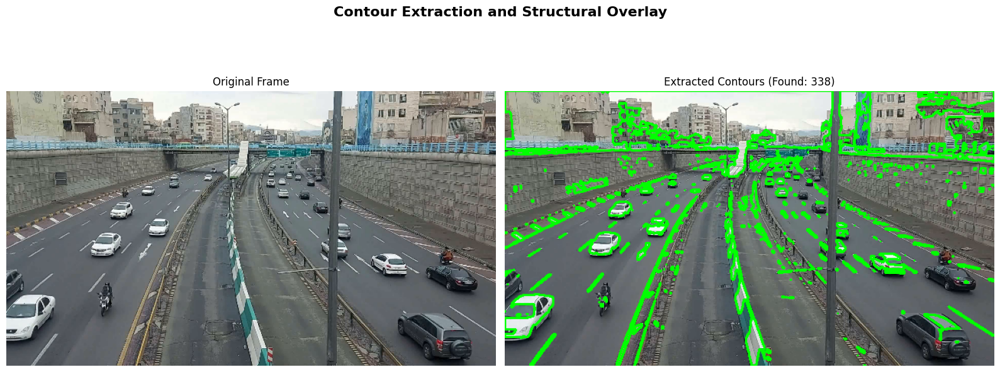

In [17]:
import cv2
import matplotlib.pyplot as plt

# Read a frame from the video source
cap = cv2.VideoCapture(output_filename)
success, frame = cap.read()
cap.release()

if success:
    # Resize and prepare grayscale image
    frame_resized = cv2.resize(frame, (640, 360))
    gray_img = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2GRAY)
    blurred_img = cv2.GaussianBlur(gray_img, (5, 5), 0)

    # Generate a binary mask using simple thresholding
    _, thresh_base = cv2.threshold(blurred_img, 127, 255, cv2.THRESH_BINARY)

    # Clone the original resized image to draw contours on it
    contour_canvas_bgr = frame_resized.copy()

    # Extract external contours
    contours_found, hierarchy = cv2.findContours(
        thresh_base,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Draw all detected contours onto our canvas in bright green with line thickness of 2
    cv2.drawContours(contour_canvas_bgr, contours_found, -1, (0, 255, 0), 2)

    # Convert canvas to RGB for plotting
    contour_canvas_rgb = cv2.cvtColor(contour_canvas_bgr, cv2.COLOR_BGR2RGB)
    original_rgb = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2RGB)

    # Plot comparison
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    axes[0].imshow(original_rgb)
    axes[0].set_title("Original Frame", fontsize=12)
    axes[0].axis("off")

    axes[1].imshow(contour_canvas_rgb)
    axes[1].set_title(f"Extracted Contours (Found: {len(contours_found)})", fontsize=12)
    axes[1].axis("off")

    plt.suptitle("Contour Extraction and Structural Overlay", fontsize=16, weight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f"Error: Unable to open the video at {output_filename}")

## **Conclusion**

This project successfully demonstrated a complete, modular computer vision pipeline to analyze road traffic and count vehicles using standard image processing operations on `/content/SampleVideo_LowQuality.mp4`:

* **Pipeline Robustness**: While individual operations like thresholding, edge operators (Canny/Sobel), and color conversions (HSV/LAB) lay the foundation, they are highly sensitive to illumination and background artifacts when applied statically (yielding over **338 noisy contours** in raw frames).
* **Noise Suppression**: Applying structured **morphological closing and opening operations** successfully eliminated high-frequency roadway noise while preserving cohesive vehicle silhouettes.
* **Tracking and Statistics**: Integrating **MOG2 background subtraction** with centroid-based tracking across a virtual counting line achieved reliable, noise-free vehicle tracking, counting **58 total vehicles** with a steady cumulative growth curve and real-time density monitoring across the **~41.7-second** video clip.



### **Recommendations for Future Enhancements**
1. **Deep Learning Integration**: Upgrade the foreground detection layer to a pre-trained **YOLO (You Only Look Once)** model to classify specific vehicle types (cars vs. trucks) and avoid false positives from shadow intersections.
2. **Perspective Calibration**: Implement an Inverse Perspective Mapping (IPM) warp to map the 3D perspective to a 2D bird's-eye view, ensuring uniform speed estimates and linear distance tracking.